<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">02.1 · Tweets: baseline sentiment tools</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">How far do ready-made tools get without any training?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/01_text_mining/02_project_tweets/02.1_Tweets_Baseline_Tools.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#tweets)

## 🎯 Objectives
By the end of this notebook you will be able to:

- apply four **ready-made sentiment tools** to tweets, with no training at all: **TextBlob**, **VADER**, **SentiWordNet** (via NLTK) and **AFINN**;
- turn each tool's score into a `pos` / `neg` prediction and evaluate it with a **confusion matrix** and a **classification report**;
- compare the tools on one chart and against the simplest baseline of all: **always predict the majority class** (83.2%);
- look at the tweets that **every** tool gets wrong and see why (irony, very short tweets, mixed feelings).

**⏱️ Duration:** ≈ 20 min · **📋 Prerequisites:** [02.0 · EDA](02.0_Tweets_EDA.ipynb) · Lesson 02 (precision, recall, F1, confusion matrix) · **▶️ How to use:** run the cells in order with `Shift`+`Enter`. Everything runs on a laptop CPU; nothing here needs a GPU. The outputs you see are saved from the original run, so you can also just read the notebook.

<sub>Based on the Text Mining project by Diogo Freitas, João Francisco Botas and Ana Sofia Trabulo (ISCTE, 2024/25).</sub>

## 📑 Contents

1. [⚙️ Project setup](#sec-1)
2. [🧹 Simple preprocessing](#sec-2)
3. [🧰 Applying sentiment analysis tools](#sec-3)
    - 3.1 [TextBlob](#sec-3-1) · 3.2 [VADER Sentiment](#sec-3-2) · 3.3 [SentiWordNet (via NLTK)](#sec-3-3) · 3.4 [AFINN](#sec-3-4)
4. [⚖️ Comparing the models](#sec-4)
5. [🏆 Comparing the results](#sec-5)
6. [📌 Summary](#sec-6)

<a id="sec-1"></a>

# 1. ⚙️ Project setup

In [ ]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "textblob", "vaderSentiment", "afinn", "wordcloud"],
                   check=True)
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())

sys.path.insert(0, str(ROOT))
print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

##### Imports

In [1]:
import pandas as pd
from pathlib import Path
import os
import seaborn as sns
import matplotlib.pyplot as plt
import gzip
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, TreebankWordTokenizer
from collections import Counter
from wordcloud import WordCloud
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import sys

from src.paths import data_dir

# Folder with the tweets (data/tweets/), downloaded from the data release the first time
TWEETS = data_dir("tweets") / "tweets"

##### Shared functions

In [2]:
# Helpers shared by all the notebooks of the tweet project (src/tweet_tools.py):
# basic cleaning, confusion matrix and classification report
from src.tweet_tools import plot_confusion_matrix, print_classification_report, clean_text

### Reading the data

In [3]:
df_train, df_test = pd.read_csv(TWEETS / "tweets_train.csv"), pd.read_csv(TWEETS / "tweets_test.csv")

df_train, df_test

(            tweet                                               text class
 0      1229448571                  some count sheep, you count cats    pos
 1      1230261573  We haven't been to Turning Stone in ages! Have...   pos
 2      1228861415                                           What up    pos
 3      1228489365                                          I'm good    pos
 4      1229800235  I know, wonder if USER is going to buy an apar...   pos
 ...           ...                                                ...   ...
 39931  1230130325                                    LOL- F, please    pos
 39932  1229250927  I wish I could do that too! But it ain't happe...   neg
 39933  1228710021                    I &lt;3 my boyfriend's family.    pos
 39934  1228100681                                               404    neg
 39935  1229022675  RT USER ok i can still tweet but admit i am a ...   pos
 
 [39936 rows x 3 columns],
            tweet                                          

<a id="sec-2"></a>

# 2. 🧹 Simple preprocessing

We only remove links from the tweets ("https" or "www"), lowercase the text and remove stopwords.

In [5]:
# Download the NLTK stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

df_test['clean_text'] = df_test['text'].astype(str).apply(clean_text, stop_words=stop_words)

[nltk_data] Downloading package stopwords to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [6]:
# There were a few missing values in the text
df_test.dropna(subset=['text'], inplace=True)
df_test

,tweet,text,class,clean_text
0,1229614408,G Night world,pos,g night world
1,1229158792,Morning all just got home from taking my daug...,pos,morning got home taking daughter doc's. want m...
2,1228398639,thanks for the follow - how are you connected ...,pos,"thanks follow - connected b&gc? board 6 years,..."
3,1229411644,re: Home Depot...hey! maybe we'll see you ther...,pos,re: home depot...hey! maybe see there... : )
4,1230107823,tak jsem poprve v zivote napsala zpravicku na ...,pos,tak jsem poprve v zivote napsala zpravicku na ...
...,...,...,...,...
9980,1228266179,Productive day today FTW! Bought/wrapped gifts...,pos,productive day today ftw! bought/wrapped gifts...
9981,1229022249,Thanks,pos,thanks
9982,1229969913,Nice! Thanks for the info,pos,nice! thanks info
9983,1230580122,"daaaaamn... i shoulda came down there, but you...",neg,"daaaaamn... shoulda came there, cant buy recor..."


We tried with and without stopwords and decided to remove them for this baseline phase. An example where we expected that keeping them would help, but it did not:

"my bad": tweet 1229135196 -> every model gets this tweet wrong

- With stopwords:

```
All models got the true class wrong at the same time in 784 cases, i.e. in 7.9% of the tweets in the test set.
All models got the true class right at the same time in 6030 cases, i.e. in 60.4% of the tweets in the test set.
```

- Without stopwords:

```
All models got the true class wrong at the same time in 912 cases, i.e. in 9.1% of the tweets in the test set.
All models got the true class right at the same time in 6238 cases, i.e. in 62.5% of the tweets in the test set.
```

It is a trade-off, but we chose to make the models agree more, i.e. to keep the worst model agreeing with the others (we improve accuracy).

<a id="sec-3"></a>

# 3. 🧰 Applying sentiment analysis tools

<a id="sec-3-1"></a>

## 3.1 TextBlob

In [7]:
from textblob import TextBlob

def predict_textblob(text):
    analysis = TextBlob(text)
    return "pos" if analysis.sentiment.polarity >= 0 else "neg"

df_test['textblob_pred'] = df_test['clean_text'].apply(predict_textblob)

> 💡 **What to notice:** every tool in this notebook gives a score and we use the rule `score >= 0 → "pos"`. A score of exactly **0** (for example a tweet with no sentiment words at all) is therefore counted as **positive**. With 83% positive tweets this rule helps accuracy, but it also means many negative tweets are labelled positive "by default".

In [8]:
df_test

,tweet,text,class,clean_text,textblob_pred
0,1229614408,G Night world,pos,g night world,pos
1,1229158792,Morning all just got home from taking my daug...,pos,morning got home taking daughter doc's. want m...,pos
2,1228398639,thanks for the follow - how are you connected ...,pos,"thanks follow - connected b&gc? board 6 years,...",neg
3,1229411644,re: Home Depot...hey! maybe we'll see you ther...,pos,re: home depot...hey! maybe see there... : ),pos
4,1230107823,tak jsem poprve v zivote napsala zpravicku na ...,pos,tak jsem poprve v zivote napsala zpravicku na ...,pos
...,...,...,...,...,...
9980,1228266179,Productive day today FTW! Bought/wrapped gifts...,pos,productive day today ftw! bought/wrapped gifts...,pos
9981,1229022249,Thanks,pos,thanks,pos
9982,1229969913,Nice! Thanks for the info,pos,nice! thanks info,pos
9983,1230580122,"daaaaamn... i shoulda came down there, but you...",neg,"daaaaamn... shoulda came there, cant buy recor...",pos


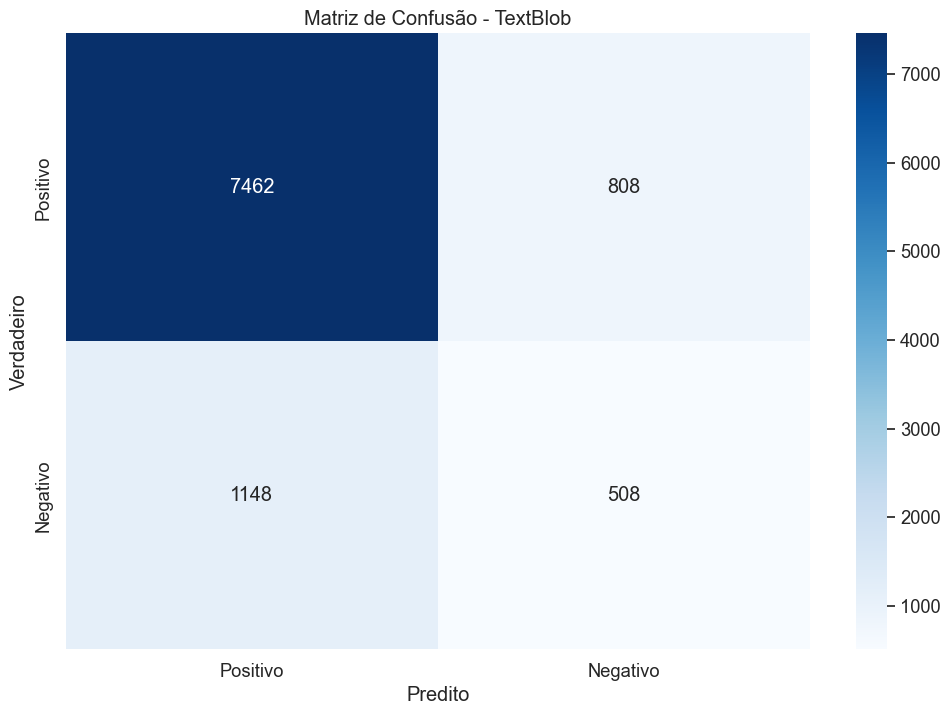

In [9]:
plot_confusion_matrix(df_test['class'], df_test['textblob_pred'], model_name="TextBlob")

In [10]:
print_classification_report(df_test['class'], df_test['textblob_pred'], model_name="TextBlob")


=== Performance report: TextBlob ===
Accuracy : 0.8029
Precision: 0.8667
Recall   : 0.9023
F1-score : 0.8841

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.39      0.31      0.34      1656
         pos       0.87      0.90      0.88      8270

    accuracy                           0.80      9926
   macro avg       0.63      0.60      0.61      9926
weighted avg       0.79      0.80      0.79      9926



> 💡 **What to notice:** the summary lines at the top (precision, recall, F1) are computed for the class **`pos`** only. Look at the detailed report: for the **`neg`** class TextBlob only reaches precision 0.39, recall 0.31 and F1 0.34. And accuracy 0.8029 is **below** the 0.832 you would get by always answering *positive*.

<a id="sec-3-2"></a>

## 3.2 VADER Sentiment

In [11]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
analyzer = SentimentIntensityAnalyzer()

def predict_vader(text):
    scores = analyzer.polarity_scores(text)
    return "pos" if scores['compound'] >= 0 else "neg"

df_test['vader_pred'] = df_test['clean_text'].apply(predict_vader)

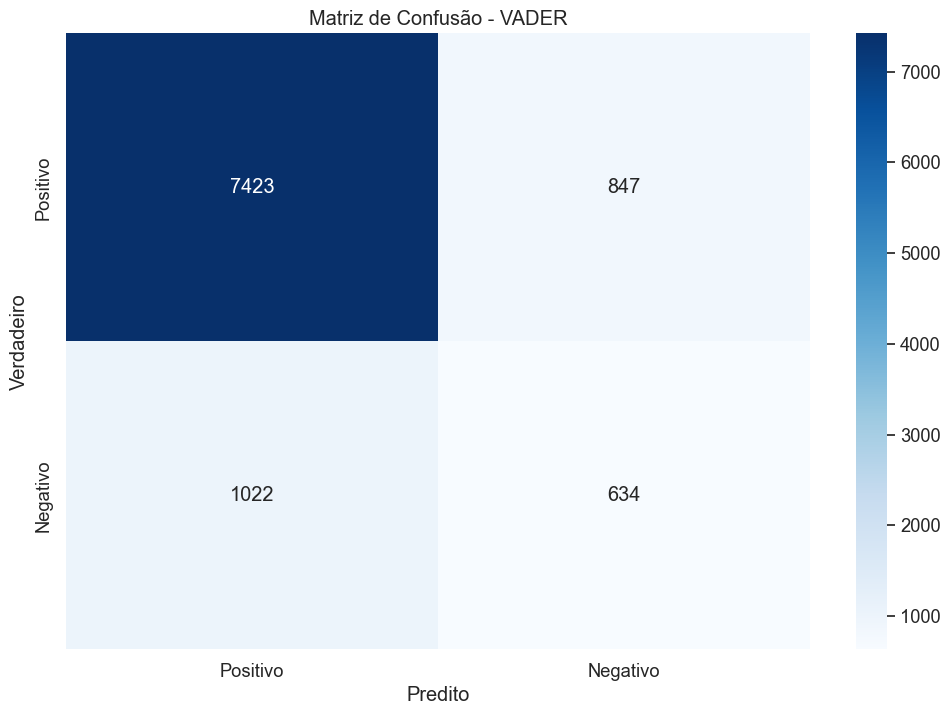

In [12]:
plot_confusion_matrix(df_test['class'], df_test['vader_pred'], model_name="VADER")

In [13]:
print_classification_report(df_test['class'], df_test['vader_pred'], model_name="VADER")


=== Performance report: VADER ===
Accuracy : 0.8117
Precision: 0.8790
Recall   : 0.8976
F1-score : 0.8882

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.43      0.38      0.40      1656
         pos       0.88      0.90      0.89      8270

    accuracy                           0.81      9926
   macro avg       0.65      0.64      0.65      9926
weighted avg       0.80      0.81      0.81      9926



<a id="sec-3-3"></a>

## 3.3 SentiWordNet (via NLTK)

In [14]:
from nltk.corpus import sentiwordnet as swn
from nltk.corpus import wordnet as wn
nltk.download('punkt_tab')
nltk.data.find('tokenizers/punkt_tab')
nltk.download('wordnet')
nltk.download('sentiwordnet')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package sentiwordnet to
[nltk_data]     ~/nltk_data...
[nltk_data]   Package sentiwordnet is already up-to-date!


True

https://medium.com/@nidhikayadav/sentiment-analysis-with-python-sentiwordnet-fd07ffc557

We need to tokenize the text and use [synsets](https://www.geeksforgeeks.org/nlp-synsets-for-a-word-in-wordnet/).

In [15]:
# Compute the polarity with SentiWordNet
def predict_sentiwordnet(text):
    tokens = word_tokenize(text)
    sentiment_score = 0
    for word in tokens:
        # Try to get the WordNet synsets of the word
        synsets = wn.synsets(word)
        if synsets:
            # Use the first synset of the word
            senti_synset = swn.senti_synset(synsets[0].name())
            sentiment_score += senti_synset.pos_score() - senti_synset.neg_score()

    return "pos" if sentiment_score >= 0 else "neg"

# Apply the function to the text
df_test['sentiwordnet_pred'] = df_test['clean_text'].apply(predict_sentiwordnet)

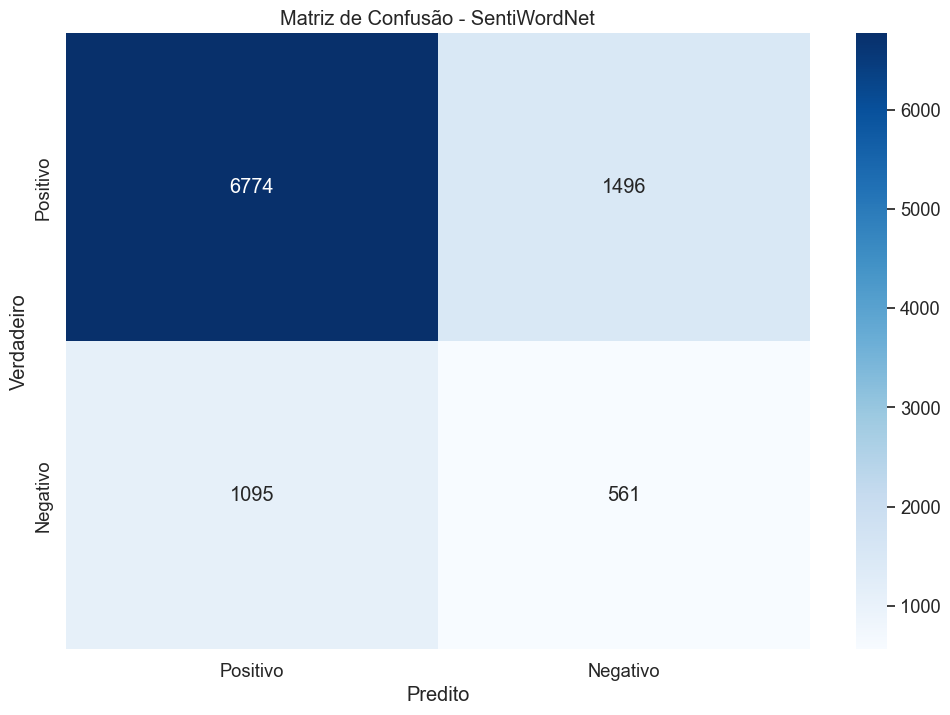


=== Performance report: SentiWordNet ===
Accuracy : 0.7390
Precision: 0.8608
Recall   : 0.8191
F1-score : 0.8395

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.27      0.34      0.30      1656
         pos       0.86      0.82      0.84      8270

    accuracy                           0.74      9926
   macro avg       0.57      0.58      0.57      9926
weighted avg       0.76      0.74      0.75      9926



In [16]:
# Evaluate the performance
plot_confusion_matrix(df_test['class'], df_test['sentiwordnet_pred'], model_name="SentiWordNet")
print_classification_report(df_test['class'], df_test['sentiwordnet_pred'], model_name="SentiWordNet")

> 💡 **What to notice:** SentiWordNet is the weakest tool here (accuracy 0.7390). It always takes the **first** meaning (synset) of each word, whatever the context, so a word like *"bad"* in *"my bad"* or a slang word can get the wrong polarity.

<a id="sec-3-4"></a>

## 3.4 AFINN

In [17]:
from afinn import Afinn

# Create the analyser
afinn = Afinn()

# Predict the sentiment
def predict_afinn(text):
    score = afinn.score(text)  # returns a float
    return "pos" if score >= 0 else "neg"

# Apply the function to the text
df_test['afinn_pred'] = df_test['clean_text'].apply(predict_afinn)

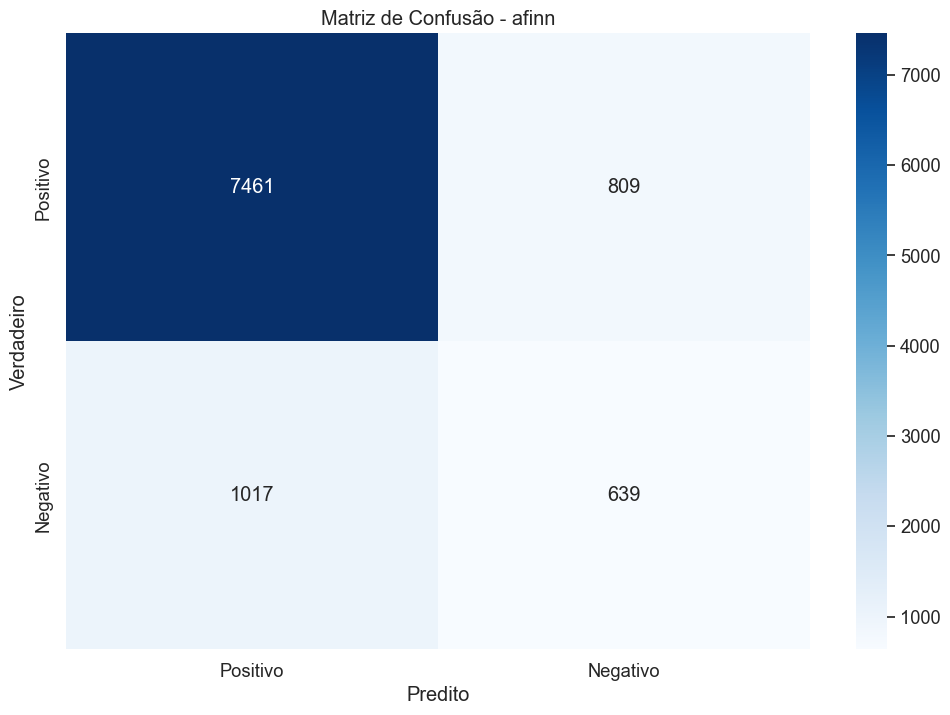


=== Performance report: afinn ===
Accuracy : 0.8160
Precision: 0.8800
Recall   : 0.9022
F1-score : 0.8910

--- Detailed report ---
              precision    recall  f1-score   support

         neg       0.44      0.39      0.41      1656
         pos       0.88      0.90      0.89      8270

    accuracy                           0.82      9926
   macro avg       0.66      0.64      0.65      9926
weighted avg       0.81      0.82      0.81      9926



In [18]:
# Evaluate the performance
plot_confusion_matrix(df_test['class'], df_test['afinn_pred'], model_name="afinn")
print_classification_report(df_test['class'], df_test['afinn_pred'], model_name="afinn")

<a id="sec-4"></a>

# 4. ⚖️ Comparing the models

In [19]:
df_test

,tweet,text,class,clean_text,textblob_pred,vader_pred,sentiwordnet_pred,afinn_pred
0,1229614408,G Night world,pos,g night world,pos,pos,pos,pos
1,1229158792,Morning all just got home from taking my daug...,pos,morning got home taking daughter doc's. want m...,pos,pos,neg,pos
2,1228398639,thanks for the follow - how are you connected ...,pos,"thanks follow - connected b&gc? board 6 years,...",neg,pos,pos,pos
3,1229411644,re: Home Depot...hey! maybe we'll see you ther...,pos,re: home depot...hey! maybe see there... : ),pos,pos,pos,pos
4,1230107823,tak jsem poprve v zivote napsala zpravicku na ...,pos,tak jsem poprve v zivote napsala zpravicku na ...,pos,pos,pos,pos
...,...,...,...,...,...,...,...,...
9980,1228266179,Productive day today FTW! Bought/wrapped gifts...,pos,productive day today ftw! bought/wrapped gifts...,pos,pos,pos,pos
9981,1229022249,Thanks,pos,thanks,pos,pos,pos,pos
9982,1229969913,Nice! Thanks for the info,pos,nice! thanks info,pos,pos,pos,pos
9983,1230580122,"daaaaamn... i shoulda came down there, but you...",neg,"daaaaamn... shoulda came there, cant buy recor...",pos,pos,pos,pos


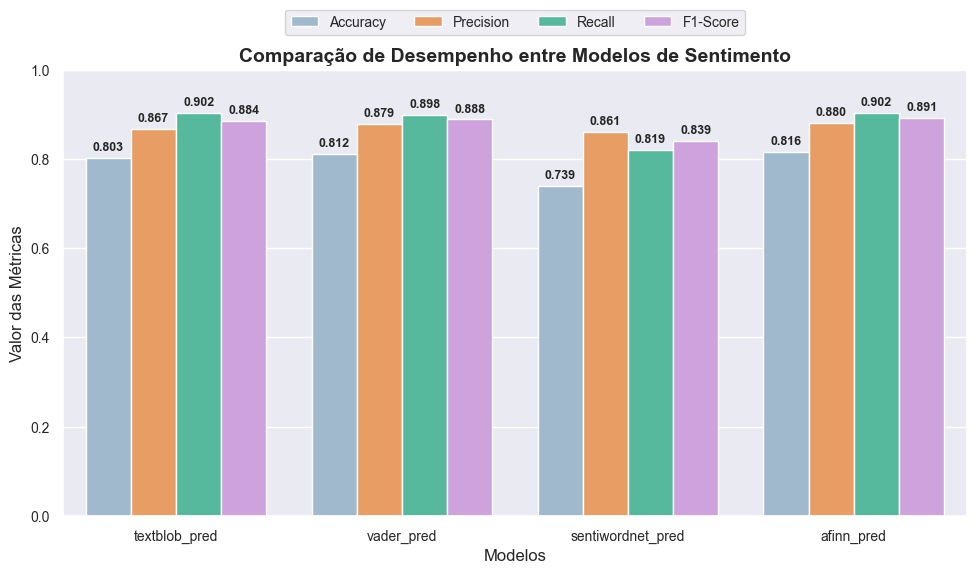

In [ ]:
# List of models to compare (every column except the ones that are not predictions)
models = [col for col in df_test.columns if col not in ['tweet', 'text', 'class', 'clean_text']]

# Dictionaries to store the metrics
accuracy_results = {}
precision_results = {}
recall_results = {}
f1_results = {}

# Compute the metrics for each model
for model in models:
    accuracy_results[model] = accuracy_score(df_test['class'], df_test[model])
    precision_results[model] = precision_score(df_test['class'], df_test[model], pos_label="pos")
    recall_results[model] = recall_score(df_test['class'], df_test[model], pos_label="pos")
    f1_results[model] = f1_score(df_test['class'], df_test[model], pos_label="pos")

# Put the results in a DataFrame
metrics_df = pd.DataFrame({
    'Model': models,
    'Accuracy': accuracy_results.values(),
    'Precision': precision_results.values(),
    'Recall': recall_results.values(),
    'F1-Score': f1_results.values()
})

# Long format to make plotting easier
metrics_df_long = metrics_df.melt(id_vars="Model", var_name="Metric", value_name="Value")

custom_palette = ['#98BAD5', '#FD9A4D', '#45CAA5', '#D39AE6']

# Grouped bar chart with the custom palette
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Model', y='Value', hue='Metric', data=metrics_df_long, palette=custom_palette)

plt.title('Performance comparison between sentiment models', fontsize=14, weight='bold')
plt.ylabel('Metric value', fontsize=12)
plt.xlabel('Models', fontsize=12)

# Y-axis scale
plt.ylim(0, 1)

# Smaller axis font
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Write the value on top of each bar
for p in ax.patches:
    height = p.get_height()
    if not pd.isna(height) and height > 0:
        ax.text(
            x=p.get_x() + p.get_width() / 2,
            y=height + 0.01,
            s=f'{height:.3f}',
            ha='center',
            va='bottom',
            fontsize=9,
            weight='bold'
        )

# Move the legend
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=4, fontsize=10)

plt.tight_layout()
plt.show()

> ⚠️ **Limitation:** precision, recall and F1 in this chart are computed with `pos_label="pos"`, i.e. only for the **majority** class. With 83% positive tweets these numbers look good (F1 ≈ 0.84–0.89) even for weak tools. The per-class reports above tell a different story for the **minority** class `neg`: F1 is only **0.34** (TextBlob), **0.40** (VADER), **0.30** (SentiWordNet) and **0.41** (AFINN). When classes are imbalanced, also report the metrics of the minority class, or the **macro** average (0.61, 0.65, 0.57, 0.65), which weighs both classes equally.

**Conclusion:** overall, all the models seem to give good results, but a closer look shows that they are worse than predicting the mode (83.2%). In other words, if the model only predicted the majority class (pos), it would get 83.2% accuracy, which is the share of that class in the test set.

To find some cases where the models get the true class completely wrong, we do a small analysis of them.

In [ ]:
model_columns = ['textblob_pred', 'vader_pred', 'sentiwordnet_pred', 'afinn_pred']

# Tweets with true class 'pos' and every prediction 'neg', or true class 'neg' and every prediction 'pos'
class_all_neg_but_pos = df_test[(df_test['class'] == 'pos') & (df_test[model_columns] == 'neg').all(axis=1)]
class_all_pos_but_neg = df_test[(df_test['class'] == 'neg') & (df_test[model_columns] == 'pos').all(axis=1)]

very_bad_preds = pd.concat([class_all_neg_but_pos, class_all_pos_but_neg])
#very_bad_preds

# Tweets with true class 'pos' and every prediction 'pos', or true class 'neg' and every prediction 'neg'
class_all_pos = df_test[(df_test['class'] == 'pos') & (df_test[model_columns] == 'pos').all(axis=1)]
class_all_neg = df_test[(df_test['class'] == 'neg') & (df_test[model_columns] == 'neg').all(axis=1)]
good_preds = pd.concat([class_all_pos, class_all_neg])

# Remaining tweets, where the models disagree
used_ids = pd.concat([very_bad_preds, good_preds])['tweet'].unique()
disagreements = df_test[~df_test['tweet'].isin(used_ids)]
disagreements

,tweet,text,class,clean_text,textblob_pred,vader_pred,sentiwordnet_pred,afinn_pred
1,1229158792,Morning all just got home from taking my daug...,pos,morning got home taking daughter doc's. want m...,pos,pos,neg,pos
2,1228398639,thanks for the follow - how are you connected ...,pos,"thanks follow - connected b&gc? board 6 years,...",neg,pos,pos,pos
6,1229006041,Pownce is shutting down. URL So close yet so far,neg,pownce shutting down. close yet far,neg,pos,pos,pos
12,1228085717,#mcl2 Ed printed out his slides for us. Very a...,pos,"#mcl2 ed printed slides us. analog, thoughtful...",pos,pos,neg,pos
14,1230437803,Observer &gt;&gt; Brees canÕt escape talk of r...,neg,observer &gt;&gt; brees canõt escape talk reco...,pos,pos,neg,neg
...,...,...,...,...,...,...,...,...
9973,1229220825,od pocetka 1 po 1,pos,od pocetka 1 po 1,pos,neg,pos,pos
9974,1229143150,298 on Wii bowling..........what a bummer....s...,neg,298 wii bowling..........what bummer....should...,pos,neg,neg,neg
9975,1230940342,Watching Merry Christmas Drake & Josh w/ Brean...,pos,watching merry christmas drake & josh w/ brean...,pos,pos,neg,pos
9976,1230492525,good morning. Long time since I have been on....,neg,good morning. long time since on. computer nas...,neg,neg,neg,pos


In [ ]:
len(disagreements)+len(good_preds)+len(very_bad_preds) == len(df_test)

True

In [ ]:
print(f"All models got the true class wrong at the same time in \033[1m{len(very_bad_preds)}\033[0m cases, i.e. in \033[1m{round(len(very_bad_preds)/len(df_test), 3)*100}%\033[0m of the tweets in the test set.")
print(f"All models got the true class right at the same time in \033[1m{len(good_preds)}\033[0m cases, i.e. in \033[1m{round(len(good_preds)/len(df_test), 3)*100}%\033[0m of the tweets in the test set.")

All models got the true class wrong at the same time in 781 cases, i.e. in 7.9% of the tweets in the test set.
All models got the true class right at the same time in 5934 cases, i.e. in 59.8% of the tweets in the test set.


With a value as high as 9.0% of the tweets, we can already conclude, with the baselines alone, that these tweets are harder to classify.

Let's look at some of these cases where the models are very wrong, to see whether the sentences are hard to detect.

> 📝 **Note:** this text was written for an earlier run; the saved output just above gives **781 tweets (7.9%)** that every tool gets wrong, and **5,934 (59.8%)** that every tool gets right.

In [ ]:
class_all_pos_but_neg[['tweet', 'text', 'class']].head(10)

,tweet,text,class
38,1229244258,Working,neg
54,1228348300,supposed to be having dinner with the family a...,neg
79,1229042405,i wish the Dr Who DVD sets were cheaper. Or I...,neg
80,1229321209,Im supposed to be done by now,neg
82,1229399708,i miss shawn elliot and gfw radio wheres ...,neg
83,1228414271,a canon a1000 but i miss my old one it was bet...,neg
105,1229915356,I wish I was born in the time of the big bans...,neg
117,1229802409,i dont know wat to do with myself today... wis...,neg
144,1227633870,very cool we must hook up next time I'm in tow...,neg
160,1230102070,another lockup of my nfs server,neg


In [ ]:
class_all_neg_but_pos[['tweet', 'text', 'clean_text', 'class']].head(10)

,tweet,text,clean_text,class
116,1230178833,"No you are correct, the problem is mine. Sorry...","no correct, problem mine. sorry misunderstanding!",pos
133,1229709600,"i woke up at 2230, and plan on spending my ent...","woke 2230, plan spending entire night working ...",pos
150,1230425497,"Goodmorning twitters btw ,vacancy is not a goo...","goodmorning twitters btw ,vacancy not good movie",pos
219,1229070563,just wrapped the Left 4 Dead shoot. We had a b...,"wrapped left 4 dead shoot. blast ""boomer's day...",pos
236,1229119456,no I have to talk to Chris and he's sleeping ...,no talk chris sleeping wore poor guy out!,pos
258,1229135196,my bad,bad,pos
368,1229206711,"Mac OS 10.5.6 is out, hoorah . Funny how I lik...","mac os 10.5.6 out, hoorah . funny like mac os ...",pos
392,1228391490,can't wait till we get more snow so I can bui...,can't wait till get snow build one - ill take ...,pos
408,1229586922,"burrito...when all else fails, get a burrito.","burrito...when else fails, get burrito.",pos
477,1229038937,"My friend is in Chicago for week, downtown, po...","friend chicago week, downtown, poor bastard.",pos


Looking only at a small set of 10 tweets that all models classify as negative while the class is positive, we cannot find a clear pattern. This is because the corpus is made of tweets, which are written informally and often contain irony or "mixed" feelings.

Still, it is worth highlighting three of these tweets from the head, which point to different situations:

| tweet | text                           | true_class | pred_class (all models) |
|-------|--------------------------------|-------|------------|
| 1229038937     | My friend is in Chicago for week, downtown, poor bastard.| pos   | neg        |
| 1229135196     | my bad   | pos   | neg        |
| 1229586922     | burrito...when all else fails, get a burrito.   | pos   | neg        |
| 1229244258 | Working | neg | pos

- Tweet 1229038937: "clearly" an ironic tweet
- Tweet 1229135196: shows regret, but the models cannot detect it because it is short and one of its words is "bad"; **NOTE**: we tested with and without stopwords and the 4 models were wrong in both situations -> "my bad" / just "bad"
- Tweet 1229586922: looks more dramatic, with negative words, but it actually shows joy about the "burrito"

We found it interesting that a tweet with only "Working" has a negative true class and all models classified it as positive.

In [ ]:
df_test[df_test['text'].str.contains('gay', case=False, na=False)]

,tweet,text,class,clean_text,textblob_pred,vader_pred,sentiwordnet_pred,afinn_pred
17,1229199512,no! my phone is just actin gay,neg,no! phone actin gay,pos,pos,neg,neg
2714,1229763303,dOMG just red-ringed of DEATHHHHHHHHHH!!! and ...,neg,domg red-ringed deathhhhhhhhhh!!! jeremy bragi...,pos,pos,pos,pos
4388,1230874784,It's gonna be cold on Saturday. That's Gays v...,neg,gonna cold saturday. that's gays vs. mormons k...,pos,neg,pos,pos
4442,1229962539,"Love You, Man, Not in Gay Way or Anything",pos,"love you, man, not gay way anything",pos,pos,pos,pos
4787,1230074528,I'm in Houston's gay neighborhood and found th...,pos,houston's gay neighborhood found this. oh irony!,pos,neg,pos,neg
5546,1230670947,what happens when you run out of Word of the G...,pos,happens run word gay words.,pos,pos,pos,pos
5602,1229220137,Playin apples to apples with the best neighbor...,pos,playin apples apples best neighbors & gaybos e...,pos,pos,pos,pos
7218,1230148353,"Apparently philip rivers is the ""main passer g...",pos,"apparently philip rivers ""main passer guy"" cha...",pos,pos,pos,pos
7414,1229705430,Cute Idea Of The Day: Every time you see a rai...,pos,cute idea day: every time see rainbow means ga...,pos,pos,pos,pos


> 💡 **What to notice:** a word list scores each word on its own. The same word (here *"gay"*) appears in positive and negative tweets, used with very different meanings and intentions, so a tool without context cannot judge it. This is one reason why the next notebooks move from fixed word lists to models that **learn from the data** and, later, models that read the **context**.

<a id="sec-5"></a>

# 5. 🏆 Comparing the results

The same four tools as in section 4, now on the metrics that matter with imbalanced classes. Every number is copied from the classification reports above (section 3); nothing is re-computed.

How to read it: each tool has three bars, **accuracy** (grey), **macro-F1** (blue, the average of the F1 of `pos` and of `neg`) and the **F1 of the `neg` class** (red). The dashed lines are the "always say `pos`" baseline: the grey one for accuracy, the blue one for macro-F1. The best tool is at the top.

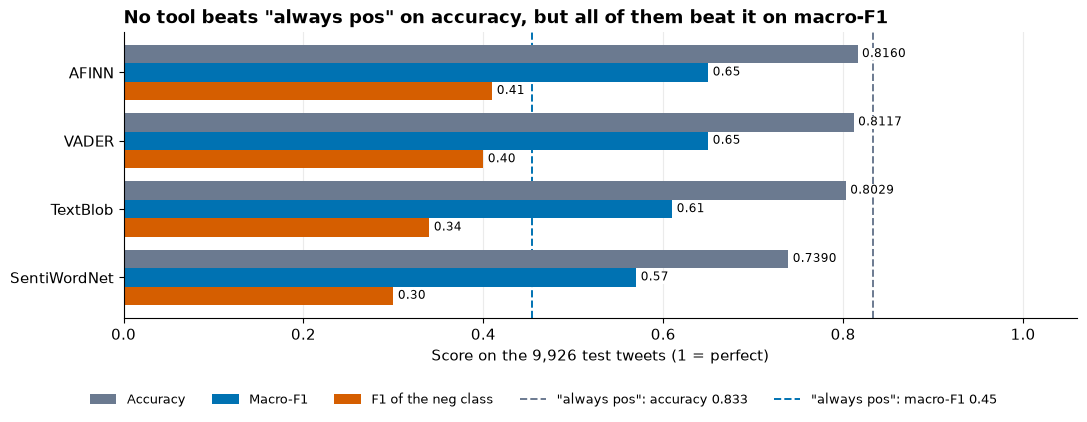

In [ ]:
# 🏆 Baseline tools on the test set: numbers copied from the reports of section 3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.plotting import apply_style, PALETTE

apply_style()

results = pd.DataFrame([
    # (model, accuracy, macro-F1, F1 of neg)
    ('TextBlob',     0.8029, 0.61, 0.34),
    ('VADER',        0.8117, 0.65, 0.40),
    ('SentiWordNet', 0.7390, 0.57, 0.30),
    ('AFINN',        0.8160, 0.65, 0.41),
], columns=["model", "accuracy", "macro_f1", "f1_neg"])

# "Always say pos" baseline, from the support column of the reports (9,926 test tweets)
n_pos, n_neg = 8270, 1656
base_acc = n_pos / (n_pos + n_neg)        # it is right for every pos and wrong for every neg
base_macro = (2 * base_acc / (1 + base_acc) + 0) / 2  # F1 of pos = 2PR/(P+R) with P=base_acc, R=1; F1 of neg = 0

# Best model at the top: sort by macro-F1 (ties broken by accuracy)
results = results.sort_values(["macro_f1", "accuracy"], ascending=False).reset_index(drop=True)
y = np.arange(len(results))

bars = [("accuracy", "Accuracy", PALETTE["grey"], 4),
        ("macro_f1", "Macro-F1", PALETTE["blue"], 2),
        ("f1_neg", "F1 of the neg class", PALETTE["red"], 2)]
h = 0.27  # height of one bar
fig, ax = plt.subplots(figsize=(11, 0.62 * len(results) + 1.4))
for k, (col, name, color, decimals) in enumerate(bars):
    pos = y + (k - 1) * h
    ax.barh(pos, results[col].fillna(0), height=h, color=color, label=name, zorder=2)
    for yi, v in zip(pos, results[col]):
        if pd.notna(v):
            ax.text(v + 0.005, yi, f"{v:.{decimals}f}", va="center", fontsize=8.5,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.3), zorder=3)
        elif col == "macro_f1":  # a missing value is shown as a note, never as a number
            ax.text(0.005, yi + h / 2, "macro-F1 and neg F1: not in the saved outputs", va="center",
                    fontsize=8.5, color=PALETTE["grey"], style="italic")

# The "always say pos" baseline (dashed lines, same colour as the metric they belong to)
ax.axvline(base_acc, color=PALETTE["grey"], ls="--", lw=1.4, zorder=1, label=f'"always pos": accuracy {base_acc:.3f}')
ax.axvline(base_macro, color=PALETTE["blue"], ls="--", lw=1.4, zorder=1, label=f'"always pos": macro-F1 {base_macro:.2f}')

ax.set_yticks(y, results["model"])
ax.set_ylim(y.max() + 0.6, y.min() - 0.6)  # reversed limits: first row at the top
ax.set_xlim(0, 1.06)
ax.set_xlabel('Score on the 9,926 test tweets (1 = perfect)')
ax.grid(axis="y", visible=False)
ax.set_title('No tool beats "always pos" on accuracy, but all of them beat it on macro-F1')
fig.tight_layout()
handles, labels = ax.get_legend_handles_labels()  # the two dashed lines come first: move them to the end
fig.legend(handles[2:] + handles[:2], labels[2:] + labels[:2], loc="upper center", bbox_to_anchor=(0.5, 0.0),
           ncol=5, fontsize=9.5)
plt.show()

> 👀 **What to notice:**
> - **Accuracy looks fine for everyone (0.74–0.82)** only because 83% of the tweets are positive: the "always `pos`" rule gets 0.833 without reading a single word, and every tool is *below* it.
> - **Macro-F1 tells the opposite story:** "always `pos`" scores only 0.45 (its F1 for `neg` is 0), while the tools reach 0.57–0.65. They *do* find some negative tweets; they just pay for it with mistakes on positive ones.
> - The red bars are the real weakness: the best `neg` F1 is **0.41** (AFINN). AFINN and VADER tie on macro-F1 (0.65); SentiWordNet is last on every metric.

<a id="sec-6"></a>

# 6. 📌 Summary

- Four ready-made tools, **no training**, same simple cleaning (lowercase, no links, no stopwords) and the same rule `score >= 0 → pos`.
- Test accuracy: **TextBlob 0.8029 · VADER 0.8117 · SentiWordNet 0.7390 · AFINN 0.8160**. All of them are **below 0.832**, the accuracy of always answering *positive*.
- The metrics of the `pos` class look good (F1 0.84–0.89), but the **`neg` class** is poorly detected (F1 0.30–0.41). With imbalanced classes, always check the minority class.
- **781 tweets (7.9%)** fool every tool at once, and **5,934 (59.8%)** are classified correctly by all of them. The failures include irony (*"poor bastard"*), very short tweets (*"my bad"*, *"Working"*) and words whose meaning depends on context.
- **Next:** in [02.2 · Lexicons](02.2_Tweets_Lexicons.ipynb) we score the tweets word by word with three lexicons (NRC EmoLex, VADER, AFINN), with and without a **negation** rule.

---
<div align="center">

⬅️ [Previous: 02.0 · Tweets: exploratory data analysis](02.0_Tweets_EDA.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 02.2 · Tweets: lexicons](02.2_Tweets_Lexicons.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>